# Assignment 2: Neural Network Comparison

**Goal:** build a classifier on a synthetic two-class dataset, compare a **linear model** with a **neural network that uses
nonlinear activations**, experiment with hidden-layer size and learning rate, record the results in a table, and explain which
model is best and why.

| Assignment item | Where it is in this notebook |
|---|---|
| 1. Build a classifier on a synthetic two-class dataset | Steps 2 to 4 |
| 2. Compare a linear model with a neural network | Step 5 |
| 3. Experiment with hidden-layer size and learning rate | Step 6 |
| 4. Record results in a comparison table | Steps 6 and 7 |
| 5. Explain which model performed best and why | Step 8 |

**Key ideas used here**
- **Binary classification:** the model outputs one score. A sigmoid turns it into a probability of class 1, and we predict class 1 when it is at least 0.5.
- **Loss function:** binary cross-entropy (`BCEWithLogitsLoss`) punishes confident wrong answers. (For more than two classes we use `CrossEntropyLoss`, as in Mini Project 2.)
- **Nonlinear activation (ReLU):** without it, stacking layers is still just a straight-line model. ReLU lets the network bend its decision boundary.
- **Metrics:** accuracy, precision, recall and a confusion matrix (explained in Step 4).
- **Validation data** is used to choose settings. **Test data** is used once, at the end.

## Step 1: Imports and setup

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Fixed seeds so your results are repeatable
torch.manual_seed(42)
np.random.seed(42)

print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1+cpu


## Step 2: Create the synthetic two-class dataset

We use the classic **two moons** dataset: two curved, interleaving shapes with a little random noise.
A single straight line cannot separate them, which makes it a good test for comparing linear and nonlinear models.

X shape: (1000, 2) | y shape: (1000,) | class counts: 500 vs 500


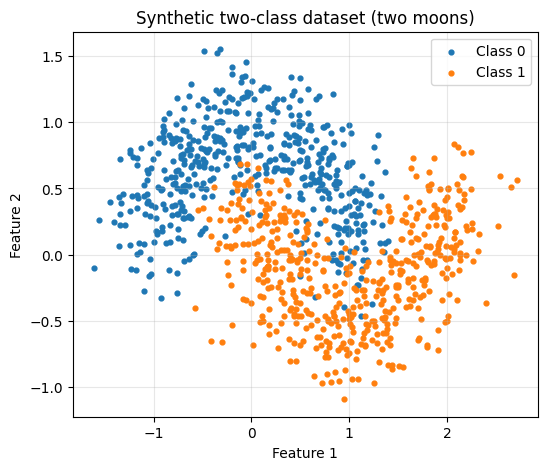

In [2]:
def make_moons(n=1000, noise=0.25, seed=42):
    """Two interleaving half-circles (class 0 and class 1) with Gaussian noise."""
    rng = np.random.default_rng(seed)
    n0 = n // 2
    n1 = n - n0
    t0 = rng.uniform(0, np.pi, n0)
    t1 = rng.uniform(0, np.pi, n1)
    moon0 = np.stack([np.cos(t0), np.sin(t0)], axis=1)
    moon1 = np.stack([1 - np.cos(t1), 0.5 - np.sin(t1)], axis=1)
    X = np.vstack([moon0, moon1]) + rng.normal(0, noise, (n, 2))
    y = np.concatenate([np.zeros(n0), np.ones(n1)])
    return X.astype(np.float32), y.astype(np.float32)


X, y = make_moons(n=1000, noise=0.25)
print("X shape:", X.shape, "| y shape:", y.shape, "| class counts:", int((y == 0).sum()), "vs", int((y == 1).sum()))

plt.figure(figsize=(6, 5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], s=12, label="Class 0")
plt.scatter(X[y == 1, 0], X[y == 1, 1], s=12, label="Class 1")
plt.title("Synthetic two-class dataset (two moons)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Step 3: Split and normalize

70% train (700 points), 15% validation (150), 15% test (150). The mean and standard deviation come from the **training set only**,
so nothing leaks from validation or test.

In [3]:
idx = np.random.permutation(len(X))
train_idx, val_idx, test_idx = idx[:700], idx[700:850], idx[850:]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

x_mean, x_std = X_train.mean(axis=0), X_train.std(axis=0)
def norm(a):
    return ((a - x_mean) / x_std).astype(np.float32)

X_train_n, X_val_n, X_test_n = norm(X_train), norm(X_val), norm(X_test)

# PyTorch tensors (labels get shape (n, 1) to match the model output)
X_train_t, X_val_t, X_test_t = (torch.tensor(a) for a in (X_train_n, X_val_n, X_test_n))
y_train_t, y_val_t, y_test_t = (torch.tensor(b).unsqueeze(1) for b in (y_train, y_val, y_test))

print("Train:", len(X_train), "| Validation:", len(X_val), "| Test:", len(X_test))

Train: 700 | Validation: 150 | Test: 150


## Step 4: Helper functions (metrics, models and training)

**Metrics, with class 1 as the "positive" class**
- **Accuracy** = correct predictions / all predictions
- **Precision** = of the points we called class 1, how many really are class 1 (TP / (TP + FP))
- **Recall** = of the points that really are class 1, how many we found (TP / (TP + FN))
- **F1** = the balance of precision and recall
- **Confusion matrix** = a 2x2 table of true class (rows) against predicted class (columns)

In [4]:
def confusion_matrix_binary(y_true, y_pred):
    """Return [[TN, FP], [FN, TP]] (rows = true class, columns = predicted class)."""
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    return np.array([[tn, fp], [fn, tp]])


def binary_metrics(y_true, y_pred):
    cm = confusion_matrix_binary(y_true, y_pred)
    tn, fp, fn, tp = (int(v) for v in cm.ravel())
    accuracy = (tp + tn) / cm.sum()
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1, "cm": cm}

In [5]:
def make_linear():
    """Linear model: one straight decision line (logistic regression)."""
    return nn.Linear(2, 1)


def make_mlp(hidden):
    """Neural network: two hidden layers with ReLU (nonlinear) activations."""
    return nn.Sequential(
        nn.Linear(2, hidden), nn.ReLU(),
        nn.Linear(hidden, hidden), nn.ReLU(),
        nn.Linear(hidden, 1),
    )


def predict(model, X_t):
    """Predicted class (0 or 1) for every row of X_t."""
    model.eval()
    with torch.no_grad():
        return (torch.sigmoid(model(X_t)) >= 0.5).float().squeeze(1).numpy()


def evaluate(model, X_t, y_np):
    return binary_metrics(y_np, predict(model, X_t))


def train(model, lr, epochs=300):
    """Train on the training set (all 700 points per step). Returns train and validation loss per epoch."""
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    train_losses, val_losses = [], []
    for epoch in range(epochs):
        model.train()
        loss = loss_fn(model(X_train_t), y_train_t)   # forward pass and loss
        optimizer.zero_grad()
        loss.backward()                               # backpropagation
        optimizer.step()                              # update the weights
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_val_t), y_val_t).item()
        train_losses.append(loss.item())
        val_losses.append(val_loss)
    return train_losses, val_losses


def plot_boundary(model, ax, title):
    """Shade the area the model assigns to each class and draw the training points on top."""
    pad = 0.5
    x_min, x_max = X_train_n[:, 0].min() - pad, X_train_n[:, 0].max() + pad
    y_min, y_max = X_train_n[:, 1].min() - pad, X_train_n[:, 1].max() + pad
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    model.eval()
    with torch.no_grad():
        prob = torch.sigmoid(model(grid)).reshape(xx.shape).numpy()
    ax.contourf(xx, yy, prob, levels=[-0.01, 0.5, 1.01], alpha=0.25, colors=["tab:blue", "tab:orange"])
    ax.scatter(X_train_n[y_train == 0, 0], X_train_n[y_train == 0, 1], s=10, c="tab:blue")
    ax.scatter(X_train_n[y_train == 1, 0], X_train_n[y_train == 1, 1], s=10, c="tab:orange")
    ax.set_title(title)
    ax.set_xlabel("Feature 1 (normalized)")
    ax.set_ylabel("Feature 2 (normalized)")

## Step 5: Linear model vs neural network (default settings)

Both models use the same learning rate (0.05) and the same number of epochs (300).
The neural network has 2 hidden layers of 16 neurons with ReLU.

Linear model validation accuracy:   84.7%
Neural network validation accuracy: 95.3%


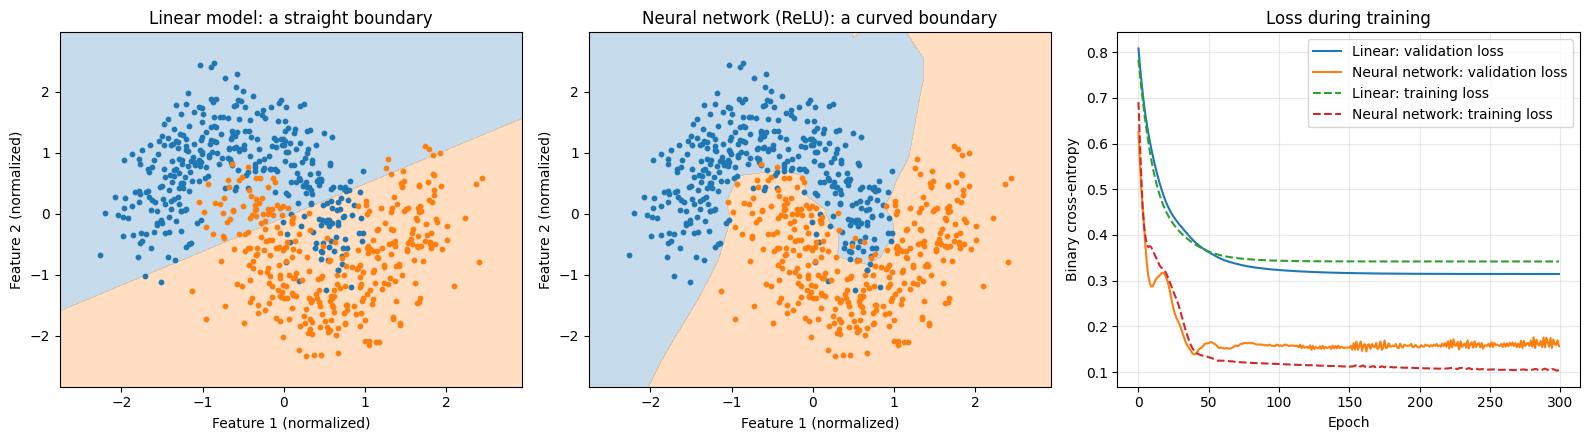

In [6]:
DEFAULT_LR = 0.05
EPOCHS = 300

torch.manual_seed(42)
linear_model = make_linear()
lin_train_loss, lin_val_loss = train(linear_model, DEFAULT_LR, EPOCHS)

torch.manual_seed(42)
mlp_model = make_mlp(16)
mlp_train_loss, mlp_val_loss = train(mlp_model, DEFAULT_LR, EPOCHS)

print(f"Linear model validation accuracy:   {evaluate(linear_model, X_val_t, y_val)['accuracy'] * 100:.1f}%")
print(f"Neural network validation accuracy: {evaluate(mlp_model, X_val_t, y_val)['accuracy'] * 100:.1f}%")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
plot_boundary(linear_model, axes[0], "Linear model: a straight boundary")
plot_boundary(mlp_model, axes[1], "Neural network (ReLU): a curved boundary")
axes[2].plot(lin_val_loss, label="Linear: validation loss")
axes[2].plot(mlp_val_loss, label="Neural network: validation loss")
axes[2].plot(lin_train_loss, "--", label="Linear: training loss")
axes[2].plot(mlp_train_loss, "--", label="Neural network: training loss")
axes[2].set_title("Loss during training")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Binary cross-entropy")
axes[2].legend()
axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("decision_boundaries.png", dpi=150)
plt.show()

## Step 6: Experiments with hidden-layer size and learning rate

We train a neural network for every combination of hidden size (2, 4, 8, 16, 32, 64) and learning rate (0.001, 0.01, 0.05, 0.1),
then compare them on the **validation** set. The **gap** column is training accuracy minus validation accuracy:
a large positive gap hints at overfitting, while low accuracy on both hints at underfitting.

In [7]:
hidden_sizes = [2, 4, 8, 16, 32, 64]
learning_rates = [0.001, 0.01, 0.05, 0.1]

results = []
for h in hidden_sizes:
    for lr in learning_rates:
        torch.manual_seed(42)
        m = make_mlp(h)
        tr_loss, va_loss = train(m, lr, EPOCHS)
        results.append({
            "hidden": h,
            "lr": lr,
            "train_acc": evaluate(m, X_train_t, y_train)["accuracy"],
            "val_acc": evaluate(m, X_val_t, y_val)["accuracy"],
            "val_loss": va_loss[-1],
            "model": m,
        })

print(f"{'Hidden':>6} | {'LR':>6} | {'Train acc':>9} | {'Val acc':>8} | {'Gap':>6} | {'Val loss':>8}")
print("-" * 60)
for r in results:
    gap = r["train_acc"] - r["val_acc"]
    print(f"{r['hidden']:>6} | {r['lr']:>6} | {r['train_acc'] * 100:>8.1f}% | {r['val_acc'] * 100:>7.1f}% | "
          f"{gap * 100:>5.1f}% | {r['val_loss']:>8.3f}")

Hidden |     LR | Train acc |  Val acc |    Gap | Val loss
------------------------------------------------------------
     2 |  0.001 |     48.7% |    62.7% | -14.0% |    0.621
     2 |   0.01 |     83.0% |    84.7% |  -1.7% |    0.332
     2 |   0.05 |     85.6% |    87.3% |  -1.8% |    0.292
     2 |    0.1 |     94.0% |    94.0% |   0.0% |    0.144
     4 |  0.001 |     80.4% |    80.7% |  -0.2% |    0.494
     4 |   0.01 |     85.1% |    87.3% |  -2.2% |    0.294
     4 |   0.05 |     94.6% |    95.3% |  -0.8% |    0.166
     4 |    0.1 |     94.0% |    94.7% |  -0.7% |    0.147
     8 |  0.001 |     83.9% |    85.3% |  -1.5% |    0.342
     8 |   0.01 |     94.6% |    94.7% |  -0.1% |    0.147
     8 |   0.05 |     95.1% |    95.3% |  -0.2% |    0.184
     8 |    0.1 |     94.7% |    94.7% |   0.0% |    0.165
    16 |  0.001 |     84.1% |    85.3% |  -1.2% |    0.314
    16 |   0.01 |     95.3% |    96.0% |  -0.7% |    0.144
    16 |   0.05 |     95.6% |    95.3% |   0.2% |    0

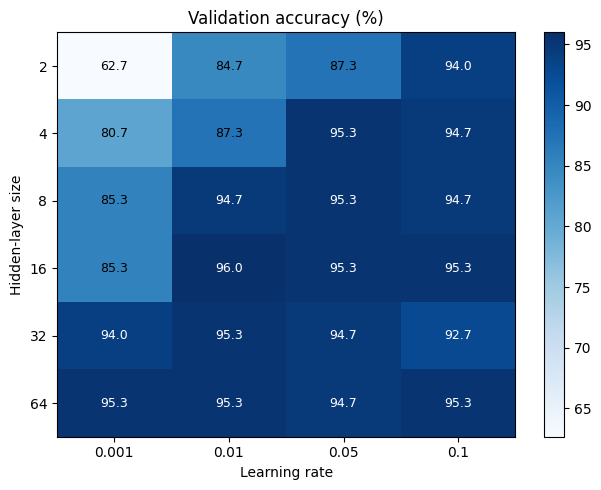

Best settings chosen on validation data: hidden size = 16, learning rate = 0.01 (validation accuracy 96.0%)


In [8]:
# Heatmap of validation accuracy for every combination
grid_acc = np.array([[next(r["val_acc"] for r in results if r["hidden"] == h and r["lr"] == lr)
                      for lr in learning_rates] for h in hidden_sizes])

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(grid_acc * 100, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(learning_rates)))
ax.set_xticklabels(learning_rates)
ax.set_yticks(range(len(hidden_sizes)))
ax.set_yticklabels(hidden_sizes)
ax.set_xlabel("Learning rate")
ax.set_ylabel("Hidden-layer size")
ax.set_title("Validation accuracy (%)")
for i in range(len(hidden_sizes)):
    for j in range(len(learning_rates)):
        ax.text(j, i, f"{grid_acc[i, j] * 100:.1f}", ha="center", va="center",
                color="white" if grid_acc[i, j] * 100 > grid_acc.max() * 100 - 4 else "black", fontsize=9)
fig.colorbar(im)
plt.tight_layout()
plt.savefig("hyperparameter_heatmap.png", dpi=150)
plt.show()

# Choose the best settings using VALIDATION data only (ties go to the lower validation loss)
best = max(results, key=lambda r: (r["val_acc"], -r["val_loss"]))
best_model = best["model"]
print(f"Best settings chosen on validation data: hidden size = {best['hidden']}, learning rate = {best['lr']} "
      f"(validation accuracy {best['val_acc'] * 100:.1f}%)")

## Step 7: Comparison table on the test set

The test set has not been used for training or for choosing settings, so this is the honest comparison.

In [9]:
rows = [
    ("Linear model", linear_model),
    ("Neural network (default: 16 hidden, lr 0.05)", mlp_model),
    (f"Neural network (best: {best['hidden']} hidden, lr {best['lr']})", best_model),
]

comparison = []
for name, m in rows:
    comparison.append({
        "name": name,
        "train": evaluate(m, X_train_t, y_train),
        "val": evaluate(m, X_val_t, y_val),
        "test": evaluate(m, X_test_t, y_test),
    })

print(f"{'Model':<46} | {'Train':>6} | {'Val':>6} | {'Test':>6} | {'Precision':>9} | {'Recall':>6} | {'F1':>5}")
print("-" * 100)
for c in comparison:
    t = c["test"]
    print(f"{c['name']:<46} | {c['train']['accuracy'] * 100:>5.1f}% | {c['val']['accuracy'] * 100:>5.1f}% | "
          f"{t['accuracy'] * 100:>5.1f}% | {t['precision']:>9.3f} | {t['recall']:>6.3f} | {t['f1']:>5.3f}")

Model                                          |  Train |    Val |   Test | Precision | Recall |    F1
----------------------------------------------------------------------------------------------------
Linear model                                   |  83.3% |  84.7% |  90.0% |     0.891 |  0.877 | 0.884
Neural network (default: 16 hidden, lr 0.05)   |  95.6% |  95.3% |  94.0% |     0.924 |  0.938 | 0.931
Neural network (best: 16 hidden, lr 0.01)      |  95.3% |  96.0% |  94.7% |     0.925 |  0.954 | 0.939


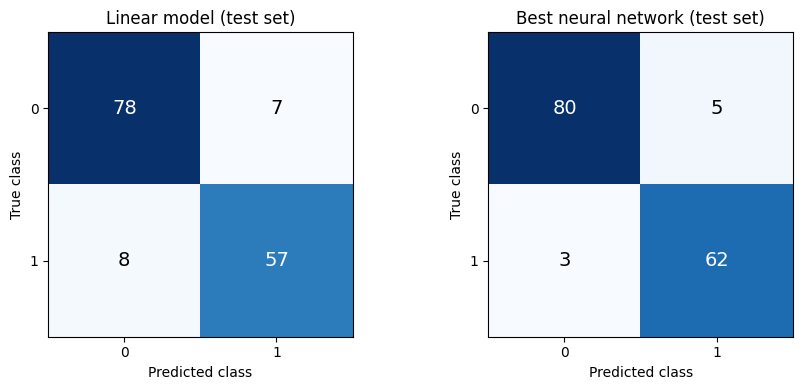

In [10]:
# Confusion matrices on the test set
def plot_cm(cm, ax, title):
    ax.imshow(cm, cmap="Blues")
    ax.set_title(title)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=14,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
plot_cm(comparison[0]["test"]["cm"], axes[0], "Linear model (test set)")
plot_cm(comparison[2]["test"]["cm"], axes[1], "Best neural network (test set)")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

## Step 8: Which model performed best, and why?

In [11]:
lin = comparison[0]["test"]["accuracy"]
best_nn = comparison[2]["test"]["accuracy"]
winner = "neural network" if best_nn > lin else ("linear model" if lin > best_nn else "both models equally")

print(f"Linear model test accuracy:        {lin * 100:.1f}%")
print(f"Best neural network test accuracy: {best_nn * 100:.1f}%  (hidden = {best['hidden']}, lr = {best['lr']})")
print(f"Best performer on the test set: {winner}")
print()
worst = min(results, key=lambda r: r["val_acc"])
print(f"Weakest neural network setting: hidden = {worst['hidden']}, lr = {worst['lr']} "
      f"(validation accuracy {worst['val_acc'] * 100:.1f}%)")
biggest_gap = max(results, key=lambda r: r["train_acc"] - r["val_acc"])
print(f"Largest train/validation gap: hidden = {biggest_gap['hidden']}, lr = {biggest_gap['lr']} "
      f"({(biggest_gap['train_acc'] - biggest_gap['val_acc']) * 100:.1f} points)")

Linear model test accuracy:        90.0%
Best neural network test accuracy: 94.7%  (hidden = 16, lr = 0.01)
Best performer on the test set: neural network

Weakest neural network setting: hidden = 2, lr = 0.001 (validation accuracy 62.7%)
Largest train/validation gap: hidden = 32, lr = 0.1 (3.6 points)


**Why the results look the way they do**

- **The data is not linearly separable.** The two moons curve around each other, so no straight line can split them.
  A linear model can only draw one straight boundary, which is why it misclassifies points in the overlapping region
  (this is *underfitting*: the model is too simple for the pattern).
- **Nonlinear activations are what make the difference.** ReLU lets each hidden layer bend and combine straight pieces
  into a curved boundary. You can see this in the decision-boundary pictures in Step 5.
- **Hidden-layer size controls flexibility.** Very few neurons limit how well the boundary can bend. More neurons give a more flexible boundary,
  and a very large network can start to memorize noise (*overfitting*), which shows up as a large training-minus-validation gap.
- **Learning rate controls how fast and how steadily training moves.** A very small rate may not finish learning in 300 epochs,
  while a very large one can make training jump around. Check the table and heatmap to see which rates worked best here.
- **Settings were chosen on validation data and judged on test data.** That keeps the final test score honest.

**Write your own conclusion here** (2 to 4 sentences, using the numbers printed above): which model performed best,
what you saw in the table, and which setting you would pick and why.

> *Your conclusion:*

**Your conclusion:**

The neural network performed best, reaching 94.7% test accuracy compared with 90.0% for the linear model. The classes are curved (two interleaving half-circles), so a straight line cannot separate them fully, while the ReLU network can bend its decision boundary around the shapes. The best setting was 16 hidden units with a learning rate of 0.01. The weakest setting, 2 hidden units with a learning rate of 0.001, reached only 62.7% validation accuracy because the network was too small and learned too slowly. The largest train/validation gap (3.6 points) appeared at 32 hidden units with a learning rate of 0.1, which suggests a bigger network and a high learning rate start to overfit and become less stable. I would pick 16 hidden units with a learning rate of 0.01.